# Hospital Segmentation Study

## Patient Segmentation Using Healthcare Utilization, Billing and Admission Data

### Data Analyst Internship Project

This project focuses on identifying actionable patient segments using healthcare utilization, billing, admissions and medical record data[cite: 1].

The analysis compares RFM-style segmentation and K-Means clustering to support data-driven healthcare decision making[cite: 1].

# Import Libraries and Setup
This section imports the required Python libraries for data manipulation, visualization and analysis.

The dataset path is also configured and display settings are adjusted to improve readability throughout the notebook.

In [1]:
# ==============================
# Import Libraries and Setup
# ==============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display Settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

# Dataset Path
DATA_PATH = Path(
    r"D:\Healthcare-Segmentation\data\raw\hospital_100k"
)

# Verify Dataset Location
print(f"Dataset Path: {DATA_PATH.resolve()}")

if DATA_PATH.exists():
    print("Dataset folder found successfully.")
else:
    print("WARNING: Dataset folder not found.")

Dataset Path: D:\Healthcare-Segmentation\data\raw\hospital_100k
Dataset folder found successfully.


# Data Loading
The healthcare dataset consists of multiple CSV files containing patient information, appointments, admissions, billing records, laboratory results and operational healthcare data.

In this step, all available datasets are loaded and stored as separate tables for further analysis.

In [2]:
# Load all CSV files from the dataset directory
csv_files = list(DATA_PATH.glob("*.csv"))

print(f"CSV Files Found: {len(csv_files)}\n")

tables = {}

for file in csv_files:

    df = pd.read_csv(
        file,
        low_memory=False
    )

    table_name = file.stem
    tables[table_name] = df

    print(
        f"{table_name:<25}"
        f" Rows: {df.shape[0]:>8,}"
        f" | Columns: {df.shape[1]:>3}"
    )

print("\nAll datasets loaded successfully.")

CSV Files Found: 33

admissions                Rows:    2,000 | Columns:   6
allergies                 Rows:       20 | Columns:   3
appointments              Rows:  100,000 | Columns:   6
beds                      Rows:      600 | Columns:   4
billing                   Rows:   20,000 | Columns:   6
billing_items             Rows:   40,000 | Columns:   4
departments               Rows:       12 | Columns:   4
doctors                   Rows:       80 | Columns:   5
insurance_policies        Rows:    4,000 | Columns:   6
insurance_providers       Rows:       10 | Columns:   6
inventory_categories      Rows:        8 | Columns:   3
inventory_items           Rows:      150 | Columns:   6
lab_requests              Rows:   12,000 | Columns:   6
lab_results               Rows:   11,000 | Columns:   5
lab_tests                 Rows:       40 | Columns:   4
medical_records           Rows:   25,000 | Columns:   6
medications               Rows:      120 | Columns:   6
patients                  R

# Dataset Overview
After loading all datasets, an overview of each table is generated to understand the data landscape.

This summary includes:

1. Number of records
2. Number of columns
3. Duplicate rows
4. Missing values
5. Missing value percentage

The overview helps identify potential data quality issues before proceeding with validation and feature engineering.

In [3]:
# Create dataset summary
summary = []

for table_name, df in tables.items():

    total_cells = df.shape[0] * df.shape[1]
    missing_cells = df.isnull().sum().sum()

    summary.append({
        "Table": table_name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Duplicate Rows": df.duplicated().sum(),
        "Missing Cells": missing_cells,
        "Missing Percentage (%)": round(
            (missing_cells / total_cells) * 100,
            2
        ) if total_cells > 0 else 0
    })

# Create summary dataframe
dataset_summary = pd.DataFrame(summary)

# Sort by row count
dataset_summary = dataset_summary.sort_values(
    by="Rows",
    ascending=False
)

# Reset index for clean display
dataset_summary = dataset_summary.reset_index(
    drop=True
)

print(f"Total Tables: {len(dataset_summary)}")
print(f"Summary Shape: {dataset_summary.shape}")

display(dataset_summary)

Total Tables: 33
Summary Shape: (33, 6)


,Table,Rows,Columns,Duplicate Rows,Missing Cells,Missing Percentage (%)
0,appointments,100000,6,0,30040,5.01
1,billing_items,40000,4,0,0,0.00
2,medical_records,25000,6,0,0,0.00
3,prescription_items,22000,6,0,0,0.00
4,billing,20000,6,0,0,0.00
5,payments,18000,5,0,0,0.00
6,prescriptions,15000,5,0,0,0.00
7,lab_requests,12000,6,0,0,0.00
8,lab_results,11000,5,0,0,0.00
9,patients,8000,9,0,0,0.00


# Data Validation
Before performing segmentation, data quality checks are conducted to ensure data integrity and consistency across all datasets.

This validation includes:

1. Foreign key relationship verification
2. Primary key uniqueness checks
3. Referential integrity validation
4. Duplicate key identification
Reliable relationships between tables are essential for creating accurate patient-level features.

In [4]:
# ==========================================
# Relationship Validation and Key Integrity
# ==========================================

relationships = [
    ("appointments", "patient_id", "patients", "id"),
    ("admissions", "patient_id", "patients", "id"),
    ("billing", "patient_id", "patients", "id"),
    ("medical_records", "patient_id", "patients", "id"),
    ("lab_requests", "medical_record_id", "medical_records", "id"),
    ("lab_results", "request_id", "lab_requests", "id"),
    ("admissions", "bed_id", "beds", "id"),
    ("billing_items", "billing_id", "billing", "id")
]

print("=" * 60)
print("RELATIONSHIP VALIDATION")
print("=" * 60)

for child, child_col, parent, parent_col in relationships:

    child_df = tables[child]
    parent_df = tables[parent]

    unmatched_records = (
        ~child_df[child_col].isin(parent_df[parent_col])
    ).sum()

    print(
        f"{child}.{child_col} -> {parent}.{parent_col}"
    )
    print(f"Unmatched Records: {unmatched_records}")
    print("-" * 60)

print("\n" + "=" * 60)
print("PRIMARY KEY DUPLICATE CHECK")
print("=" * 60)

for table_name, df in tables.items():

    if "id" in df.columns:

        duplicate_ids = df["id"].duplicated().sum()

        print(
            f"{table_name:<25} Duplicate IDs: {duplicate_ids}"
        )

RELATIONSHIP VALIDATION
appointments.patient_id -> patients.id
Unmatched Records: 0
------------------------------------------------------------
admissions.patient_id -> patients.id
Unmatched Records: 0
------------------------------------------------------------
billing.patient_id -> patients.id
Unmatched Records: 0
------------------------------------------------------------
medical_records.patient_id -> patients.id
Unmatched Records: 0
------------------------------------------------------------
lab_requests.medical_record_id -> medical_records.id
Unmatched Records: 0
------------------------------------------------------------
lab_results.request_id -> lab_requests.id
Unmatched Records: 0
------------------------------------------------------------
admissions.bed_id -> beds.id
Unmatched Records: 0
------------------------------------------------------------
billing_items.billing_id -> billing.id
Unmatched Records: 0
------------------------------------------------------------

PRIM

# 3.1 Date Validation
Date fields were validated to identify invalid timestamps, missing values and chronological inconsistencies.

This step is important because key healthcare metrics such as recency, length of stay and readmission rates depend on accurate date information.

In [5]:
# ==========================================
# Date Validation and Chronological Checks
# ==========================================

date_columns = {
    "appointments": ["appointment_date"],
    "admissions": ["admission_date", "discharge_date"],
    "billing": ["billing_date"],
    "medical_records": ["created_at"],
    "lab_requests": ["request_date"],
    "lab_results": ["performed_date"],
    "patients": ["date_of_birth"]
}

print("=" * 60)
print("DATE VALIDATION")
print("=" * 60)

for table_name, columns in date_columns.items():

    df = tables[table_name]

    print(f"\nTABLE: {table_name}")

    for col in columns:

        dates = pd.to_datetime(
            df[col],
            errors="coerce"
        )

        print(
            f"{col} | "
            f"Invalid Dates: {dates.isna().sum()} | "
            f"Earliest: {dates.min()} | "
            f"Latest: {dates.max()}"
        )

# ==========================================
# Admission Date Consistency Check
# ==========================================

admissions_check = tables["admissions"].copy()

admissions_check["admission_date"] = pd.to_datetime(
    admissions_check["admission_date"],
    errors="coerce"
)

admissions_check["discharge_date"] = pd.to_datetime(
    admissions_check["discharge_date"],
    errors="coerce"
)

invalid_stays = (
    admissions_check["discharge_date"]
    < admissions_check["admission_date"]
).sum()

print("\n" + "=" * 60)
print("ADMISSION CONSISTENCY CHECK")
print("=" * 60)

print(
    f"Admissions with discharge before admission: {invalid_stays}"
)

DATE VALIDATION

TABLE: appointments
appointment_date | Invalid Dates: 0 | Earliest: 2021-01-01 09:15:16 | Latest: 2025-12-31 20:43:45

TABLE: admissions
admission_date | Invalid Dates: 0 | Earliest: 2021-01-04 17:18:51 | Latest: 2025-12-30 20:47:01
discharge_date | Invalid Dates: 0 | Earliest: 2021-01-10 17:38:25 | Latest: 2026-01-11 13:11:10

TABLE: billing
billing_date | Invalid Dates: 0 | Earliest: 2021-01-01 00:00:00 | Latest: 2025-12-31 00:00:00

TABLE: medical_records
created_at | Invalid Dates: 0 | Earliest: 2021-01-01 08:30:30 | Latest: 2025-12-31 19:09:30

TABLE: lab_requests
request_date | Invalid Dates: 0 | Earliest: 2021-01-01 08:56:04 | Latest: 2025-12-31 19:02:22

TABLE: lab_results
performed_date | Invalid Dates: 0 | Earliest: 2021-01-01 15:13:23 | Latest: 2026-01-03 10:10:04

TABLE: patients
date_of_birth | Invalid Dates: 0 | Earliest: 1935-01-01 00:00:00 | Latest: 2024-12-28 00:00:00

ADMISSION CONSISTENCY CHECK
Admissions with discharge before admission: 0


# 3.2 Operational Data Quality Assessment
Operational and financial indicators are reviewed to understand healthcare service utilization, appointment outcomes, billing characteristics and hospital resource status.

This assessment helps identify data quality concerns and provides business context before feature engineering and segmentation.

In [6]:
# ==========================================
# Operational Data Quality Assessment
# ==========================================

print("=" * 60)
print("APPOINTMENT STATUS")
print("=" * 60)

display(
    tables["appointments"]["status"]
    .value_counts(dropna=False)
)

print("\n" + "=" * 60)
print("BILLING STATUS")
print("=" * 60)

display(
    tables["billing"]["status"]
    .value_counts(dropna=False)
)

print("\n" + "=" * 60)
print("BILLING AMOUNT SUMMARY")
print("=" * 60)

display(
    tables["billing"][
        ["total_amount", "paid_amount"]
    ].describe().round(2)
)

print("\n" + "=" * 60)
print("ADMISSION LENGTH OF STAY")
print("=" * 60)

admissions_check["length_of_stay_days"] = (
    admissions_check["discharge_date"]
    - admissions_check["admission_date"]
).dt.total_seconds() / 86400

display(
    admissions_check["length_of_stay_days"]
    .describe()
    .round(2)
)

print("\n" + "=" * 60)
print("CURRENT BED STATUS")
print("=" * 60)

display(
    tables["beds"]["status"]
    .value_counts(dropna=False)
)

APPOINTMENT STATUS


status
completed    83922
cancelled    11013
no_show       5065
Name: count, dtype: int64


BILLING STATUS


status
issued    20000
Name: count, dtype: int64


BILLING AMOUNT SUMMARY


,total_amount,paid_amount
count,20000.00,20000.00
mean,1697.54,1532.94
std,1588.67,1597.40
min,0.00,0.00
25%,304.85,55.15
50%,1403.07,1152.54
75%,2545.10,2414.57
max,12257.73,12257.73



ADMISSION LENGTH OF STAY


count    2000.00
mean        7.14
std         4.09
min         0.00
25%         3.61
50%         7.07
75%        10.68
max        14.61
Name: length_of_stay_days, dtype: float64


CURRENT BED STATUS


status
occupied       383
available      164
cleaning        35
maintenance     18
Name: count, dtype: int64

# 4. Feature Engineering
To support patient segmentation, key behavioral and healthcare utilization features are prepared.

Before creating patient-level metrics, date fields are converted into datetime format and a reference date is established for recency calculations.

These cleaned datasets will be used to generate:

1. Recency
2. Visit Frequency
3. Revenue Contribution
4. Billing Activity
5. Admission Behavior
6. Length of Stay
7. Medical Record Activity

In [7]:
# ==========================================
# Data Preparation for Feature Engineering
# ==========================================

from datetime import timedelta

# Convert appointment dates
appointments = tables["appointments"].copy()
appointments["appointment_date"] = pd.to_datetime(
    appointments["appointment_date"]
)

# Convert billing dates
billing = tables["billing"].copy()
billing["billing_date"] = pd.to_datetime(
    billing["billing_date"]
)

# Convert admission dates
admissions = tables["admissions"].copy()

admissions["admission_date"] = pd.to_datetime(
    admissions["admission_date"]
)

admissions["discharge_date"] = pd.to_datetime(
    admissions["discharge_date"]
)

# Reference date for recency calculation
reference_date = (
    appointments["appointment_date"].max()
    + timedelta(days=1)
)

print(
    f"Reference Date for Analysis: {reference_date.date()}"
)

Reference Date for Analysis: 2026-01-01


# Patient-Level Feature Creation
Patient-level behavioral metrics are generated by aggregating appointment and billing records.

The resulting features capture:

1. Recency of patient engagement
2. Visit frequency
3. Revenue contribution
4. Billing activity
These metrics form the foundation for both RFM-style analysis and K-Means clustering.

In [8]:
# ==========================================
# Patient-Level Feature Creation
# ==========================================

# Create patient-level feature table
patient_features = pd.DataFrame(
    index=tables["patients"]["id"]
)

# ------------------------------------------
# Recency
# Days since last appointment
# ------------------------------------------

patient_features["recency_days"] = (
    reference_date
    - appointments.groupby(
        "patient_id"
    )["appointment_date"].max()
).dt.days

# ------------------------------------------
# Frequency
# Total number of appointments
# ------------------------------------------

patient_features["visit_frequency"] = (
    appointments
    .groupby("patient_id")
    .size()
)

# ------------------------------------------
# Monetary Value
# Total revenue generated by patient
# ------------------------------------------

patient_features["total_revenue"] = (
    billing
    .groupby("patient_id")["paid_amount"]
    .sum()
)

# ------------------------------------------
# Billing Activity
# Number of billing transactions
# ------------------------------------------

patient_features["billing_count"] = (
    billing
    .groupby("patient_id")
    .size()
)

# Quick Preview
print(
    f"Patients in Feature Table: "
    f"{len(patient_features):,}"
)

patient_features.head()

Patients in Feature Table: 8,000


,recency_days,visit_frequency,total_revenue,billing_count
id,,,,
1,2.0,1045.0,335886.84,237.0
2,6.0,454.0,150597.08,89.0
3,5.0,332.0,110986.38,76.0
4,1.0,292.0,75509.74,53.0
5,8.0,275.0,88749.98,59.0


# Admission-Based Features
Admission history provides valuable insight into healthcare utilization intensity and patient complexity.

The following features are generated:

1. Admission Count: Total number of hospital admissions per patient
2. Average Length of Stay (LOS): Average duration of hospitalization
These features help identify patients requiring more intensive care and support the segmentation process.

In [9]:
# ==========================================
# Admission-Based Features
# ==========================================

# Calculate Length of Stay (LOS)
admissions["los_days"] = (
    admissions["discharge_date"]
    - admissions["admission_date"]
).dt.days

# Total admissions per patient
patient_features["admission_count"] = (
    admissions
    .groupby("patient_id")
    .size()
)

# Average Length of Stay per patient
patient_features["avg_los"] = (
    admissions
    .groupby("patient_id")["los_days"]
    .mean()
)

print("Admission-based features created successfully.")

Admission-based features created successfully.


# Medical Activity Features
Medical records provide an additional measure of patient interaction with healthcare services.

The total number of medical records associated with each patient is used as an indicator of clinical activity and healthcare utilization intensity.

This feature helps distinguish highly engaged patients from patients with limited healthcare interactions.

In [10]:
# ==========================================
# Medical Activity Features
# ==========================================

# Extract medical records table
medical_records = tables["medical_records"]

# Total medical records per patient
patient_features["medical_record_count"] = (
    medical_records
    .groupby("patient_id")
    .size()
)

print("Medical activity features created successfully.")

Medical activity features created successfully.


# Missing Value Treatment
Some engineered features may contain missing values because not every patient has admission records, billing activity or medical records.

To ensure all patients remain eligible for segmentation, missing values are replaced with zero values where no historical activity exists.

This step prepares the dataset for statistical analysis and clustering.

In [11]:
# ==========================================
# Missing Value Treatment
# ==========================================

# Replace missing values generated during
# feature engineering

patient_features = (
    patient_features
    .fillna(0)
)

# Validate missing value removal
remaining_missing = (
    patient_features
    .isnull()
    .sum()
    .sum()
)

print(
    f"Remaining Missing Values: {remaining_missing}"
)

print(
    f"Feature Table Shape: {patient_features.shape}"
)

# Preview final patient feature table
patient_features.head()

Remaining Missing Values: 0
Feature Table Shape: (8000, 7)


,recency_days,visit_frequency,total_revenue,billing_count,admission_count,avg_los,medical_record_count
id,,,,,,,
1,2.0,1045.0,335886.84,237.0,19.0,6.736842,249.0
2,6.0,454.0,150597.08,89.0,8.0,5.250000,95.0
3,5.0,332.0,110986.38,76.0,4.0,5.000000,93.0
4,1.0,292.0,75509.74,53.0,8.0,7.000000,70.0
5,8.0,275.0,88749.98,59.0,4.0,7.500000,67.0


# 5. Patient Feature Summary
After feature engineering, the patient-level dataset is reviewed to understand feature distributions, central tendencies and variability.

This summary provides initial insights into patient behavior and helps identify potential skewness, outliers and scaling requirements before clustering.

In [12]:
# ==========================================
# Patient Feature Summary
# ==========================================

print("=" * 60)
print("PATIENT FEATURE DATASET")
print("=" * 60)

print(
    f"Feature Table Shape: "
    f"{patient_features.shape}"
)

print("\nFeatures Available:")
print(patient_features.columns.tolist())

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)

display(
    patient_features
    .describe()
    .round(2)
)

PATIENT FEATURE DATASET
Feature Table Shape: (8000, 7)

Features Available:
['recency_days', 'visit_frequency', 'total_revenue', 'billing_count', 'admission_count', 'avg_los', 'medical_record_count']

DESCRIPTIVE STATISTICS


,recency_days,visit_frequency,total_revenue,billing_count,admission_count,avg_los,medical_record_count
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00
mean,140.85,12.50,3832.34,2.50,0.25,1.34,3.12
std,167.08,18.42,6536.26,4.13,0.61,3.19,4.74
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,33.00,7.00,195.81,1.00,0.00,0.00,1.00
50%,86.00,9.00,2453.73,2.00,0.00,0.00,2.00
75%,187.00,13.00,5276.13,3.00,0.00,0.00,4.00
max,1525.00,1045.00,335886.84,237.00,19.00,14.00,249.00


# 6. Feature Transformation
Several patient-level features exhibit significant positive skewness due to highly active patients and high-value healthcare utilization patterns.

To reduce the influence of extreme values and improve clustering performance, logarithmic transformation is applied to selected behavioral and financial variables.

The transformed dataset will be used for scaling and K-Means clustering.

In [13]:
# ==========================================
# Feature Transformation
# ==========================================

# Create a copy of the feature dataset
model_features = patient_features.copy()

# Features requiring log transformation
skewed_cols = [
    "visit_frequency",
    "total_revenue",
    "billing_count",
    "admission_count",
    "medical_record_count"
]

# Apply log(1 + x) transformation
for col in skewed_cols:
    model_features[col] = np.log1p(
        model_features[col]
    )

print("Log transformation completed.")

print("\nTransformed Features:")
print(model_features.columns.tolist())

# Preview transformed dataset
model_features.head()

Log transformation completed.

Transformed Features:
['recency_days', 'visit_frequency', 'total_revenue', 'billing_count', 'admission_count', 'avg_los', 'medical_record_count']


,recency_days,visit_frequency,total_revenue,billing_count,admission_count,avg_los,medical_record_count
id,,,,,,,
1,2.0,6.952729,12.724533,5.472271,2.995732,6.736842,5.521461
2,6.0,6.120297,11.922370,4.499810,2.197225,5.250000,4.564348
3,5.0,5.808142,11.617172,4.343805,1.609438,5.000000,4.543295
4,1.0,5.680173,11.232030,3.988984,2.197225,7.000000,4.262680
5,8.0,5.620401,11.393590,4.094345,1.609438,7.500000,4.219508


# 7. Exploratory Data Analysis
The transformed patient-level features are visualized to understand their distributions and evaluate the effectiveness of skew reduction.

This analysis helps identify patterns, potential outliers and overall feature behavior before applying scaling and clustering techniques.

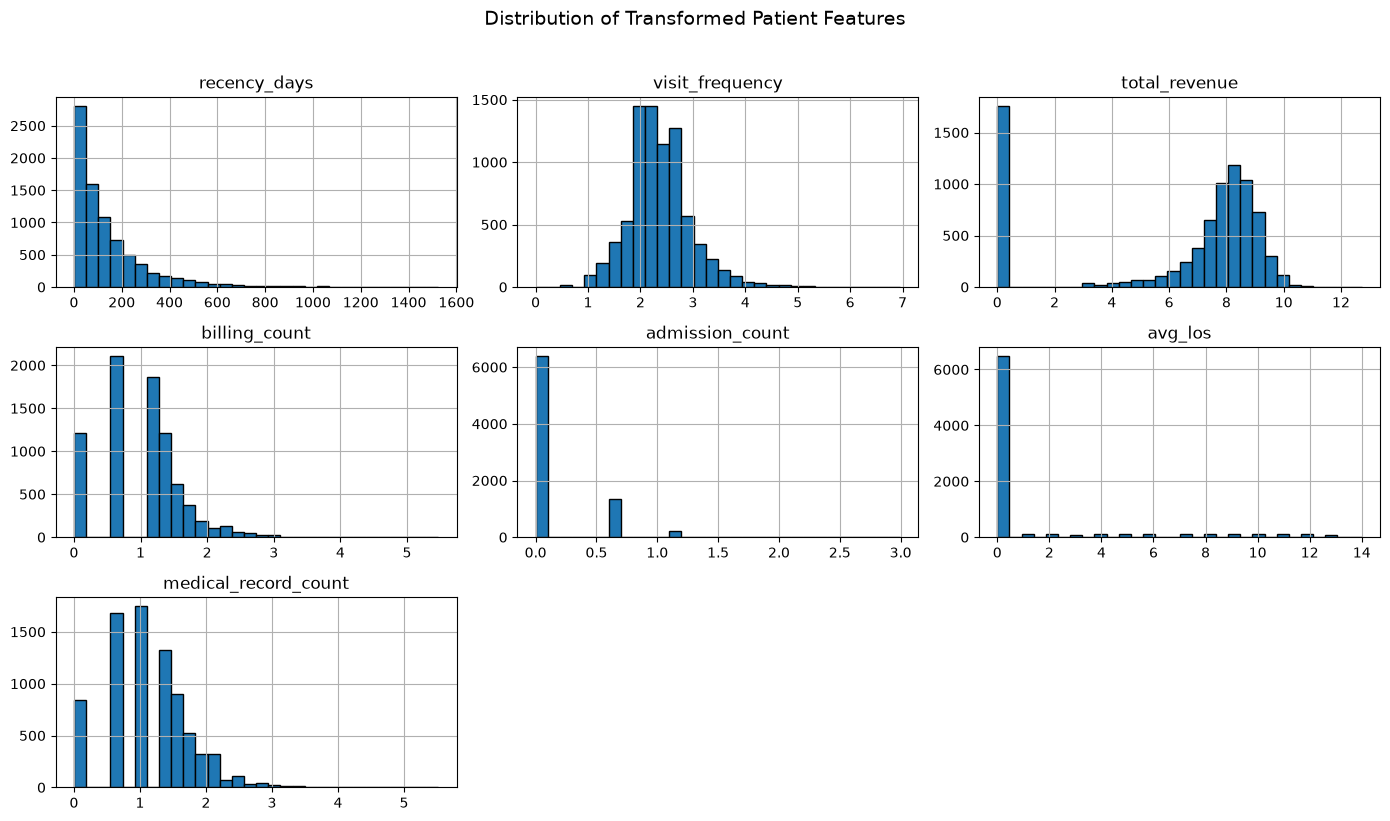

In [14]:
# ==========================================
# Exploratory Data Analysis
# Feature Distribution Visualization
# ==========================================

# Plot distributions of transformed features
model_features.hist(
    figsize=(14, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Transformed Patient Features",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

# 8. Feature Scaling
K-Means clustering is sensitive to differences in feature magnitude and scale.

To ensure that each feature contributes equally during clustering, the transformed features are standardized using StandardScaler.

Standardization converts features to a common scale with a mean of 0 and a standard deviation of 1, improving clustering performance and interpretability.

In [15]:
# ==========================================
# Feature Scaling
# ==========================================

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Standardize transformed features
scaled_features = scaler.fit_transform(
    model_features
)

print(
    f"Scaled Feature Matrix Shape: "
    f"{scaled_features.shape}"
)

print(
    f"Number of Features Used: "
    f"{model_features.shape[1]}"
)


Scaled Feature Matrix Shape: (8000, 7)
Number of Features Used: 7


# 9. Cluster Selection Using Elbow Method
The Elbow Method is used to determine the optimal number of clusters for K-Means segmentation.

Clustering inertia is calculated across multiple values of K, and the point where the rate of improvement begins to decline is considered a suitable cluster count.

In [16]:
# ==========================================
# Cluster Selection Using Elbow Method
# ==========================================

from sklearn.cluster import KMeans

# Store inertia values
inertia = []

# Evaluate cluster counts from 2 to 10
cluster_range = range(2, 11)

for k in cluster_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(scaled_features)

    inertia.append(
        model.inertia_
    )

print("Elbow Method calculations completed.")

Elbow Method calculations completed.


# Elbow Curve Visualization
The Elbow Curve illustrates how clustering inertia changes as the number of clusters increases.

The optimal number of clusters is typically identified near the point where the curve begins to flatten, indicating that additional clusters provide only marginal improvements in clustering performance.

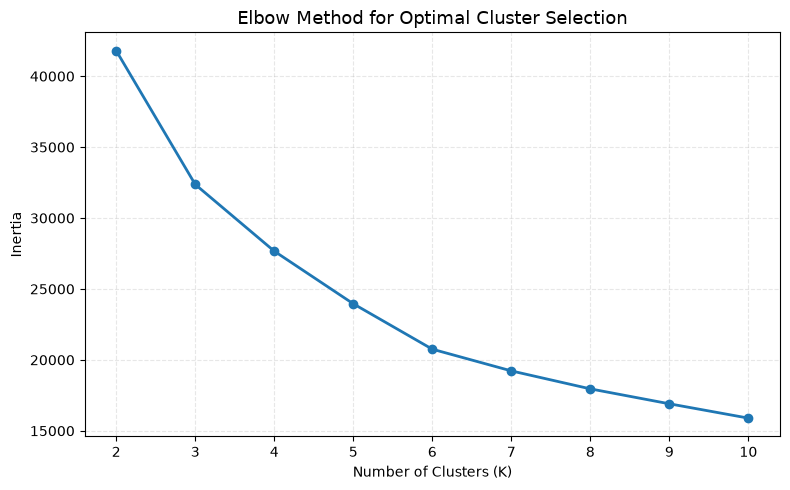

In [17]:
# ==========================================
# Elbow Curve Visualization
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    cluster_range,
    inertia,
    marker="o",
    linewidth=2
)

plt.title(
    "Elbow Method for Optimal Cluster Selection",
    fontsize=13
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Inertia"
)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()
plt.show()

# 10. Cluster Selection Using Silhouette Analysis
While the Elbow Method helps identify candidate cluster counts, Silhouette Analysis evaluates the quality of clustering by measuring how well each data point fits within its assigned cluster.

Higher silhouette scores indicate better separation between clusters and stronger cluster cohesion.

The final cluster count is selected based on a combination of silhouette scores, cluster balance and business interpretability.

In [18]:
# ==========================================
# Cluster Selection Using Silhouette Analysis
# ==========================================

from sklearn.metrics import silhouette_score

scores = []

print("=" * 60)
print("SILHOUETTE SCORES")
print("=" * 60)

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(
        scaled_features
    )

    score = silhouette_score(
        scaled_features,
        labels
    )

    scores.append(score)

    print(
        f"K = {k} | "
        f"Silhouette Score = {score:.4f}"
    )

best_k = range(2, 11)[
    np.argmax(scores)
]

print("\n" + "=" * 60)
print(f"Highest Silhouette Score at K = {best_k}")
print("=" * 60)

SILHOUETTE SCORES
K = 2 | Silhouette Score = 0.3828
K = 3 | Silhouette Score = 0.3354
K = 4 | Silhouette Score = 0.2482
K = 5 | Silhouette Score = 0.3307
K = 6 | Silhouette Score = 0.2752
K = 7 | Silhouette Score = 0.2461
K = 8 | Silhouette Score = 0.2520
K = 9 | Silhouette Score = 0.2532
K = 10 | Silhouette Score = 0.2575

Highest Silhouette Score at K = 2


# 11. Silhouette Score Visualization
The silhouette scores for different cluster counts are visualized to compare clustering performance and cluster separation quality.

Higher silhouette scores indicate better-defined clusters, while lower scores suggest overlap between segments.

The final cluster count is selected by considering silhouette scores, cluster balance and business interpretability.

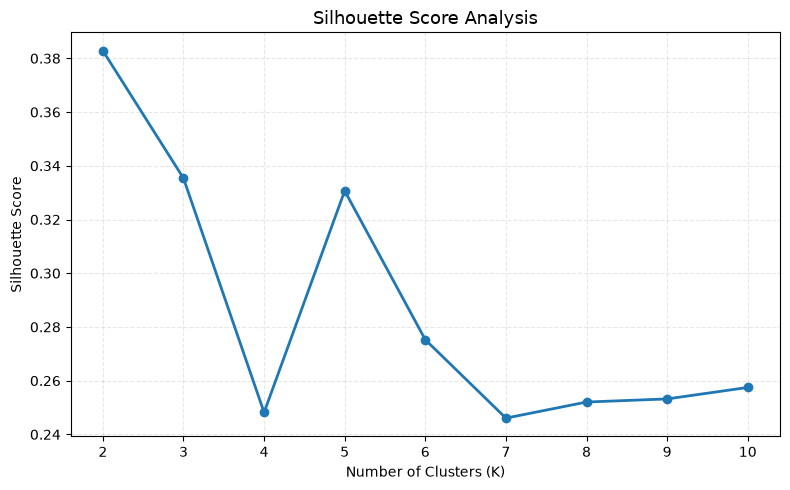

In [19]:
# ==========================================
# Silhouette Score Visualization
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    scores,
    marker="o",
    linewidth=2
)

plt.title(
    "Silhouette Score Analysis",
    fontsize=13
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Silhouette Score"
)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tight_layout()
plt.show()

# 12. Final K-Means Segmentation
Based on the Elbow Method, Silhouette Analysis and business interpretability, a five-cluster solution was selected as the final segmentation model.

This segmentation framework groups patients with similar healthcare utilization patterns, financial contribution and clinical activity.

The resulting segments will be used for profiling, revenue analysis and business recommendations.

In [20]:
# ==========================================
# Final K-Means Segmentation
# ==========================================

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

# Assign cluster labels
patient_features["cluster"] = (
    kmeans.fit_predict(
        scaled_features
    )
)

print("=" * 60)
print("CLUSTER DISTRIBUTION")
print("=" * 60)

cluster_distribution = (
    patient_features["cluster"]
    .value_counts()
    .sort_index()
)

display(cluster_distribution)

CLUSTER DISTRIBUTION


cluster
0     680
1     727
2    1046
3    4052
4    1495
Name: count, dtype: int64

# 13. Segment Profiling
After clustering, each patient segment is profiled using key behavioral, financial and healthcare utilization metrics.

The objective is to understand the characteristics of each segment and identify meaningful differences in patient behavior, revenue contribution and healthcare utilization patterns.

These profiles will be used to assign business-friendly segment names and develop targeted recommendations.

In [21]:
# ==========================================
# Segment Profiling
# ==========================================

segment_profile = (
    patient_features
    .groupby("cluster")
    .agg({
        "recency_days": "mean",
        "visit_frequency": "mean",
        "total_revenue": "mean",
        "billing_count": "mean",
        "admission_count": "mean",
        "avg_los": "mean",
        "medical_record_count": "mean"
    })
    .round(2)
)

# Improve readability
segment_profile.index.name = "Cluster"

print("=" * 60)
print("SEGMENT PROFILE SUMMARY")
print("=" * 60)

display(segment_profile)

SEGMENT PROFILE SUMMARY


,recency_days,visit_frequency,total_revenue,billing_count,admission_count,avg_los,medical_record_count
Cluster,,,,,,,
0,544.05,5.45,2631.05,1.70,0.10,0.32,1.93
1,39.09,40.69,12924.27,8.61,0.76,2.39,10.42
2,115.58,11.58,3598.83,2.30,1.16,8.12,2.90
3,101.89,10.24,3876.68,2.37,0.02,0.01,2.45
4,130.20,8.76,0.67,0.37,0.05,0.14,2.11


# 14. Revenue Share Analysis
To understand the business impact of each patient segment, revenue contribution and patient distribution are analyzed across all clusters.

This analysis helps identify high-value patient groups, prioritize resource allocation and support data-driven healthcare strategies.

The results highlight which segments contribute the most value to the healthcare network while also showing their relative size within the patient population.

In [22]:
# ==========================================
# Revenue Share Analysis
# ==========================================

segment_summary = (
    patient_features
    .groupby("cluster")
    .agg(
        patients=("cluster", "count"),
        revenue=("total_revenue", "sum"),
        avg_revenue=("total_revenue", "mean"),
        avg_frequency=("visit_frequency", "mean"),
        avg_los=("avg_los", "mean")
    )
)

# Patient share by cluster
segment_summary["patient_share_pct"] = (
    segment_summary["patients"]
    / segment_summary["patients"].sum()
    * 100
)

# Revenue share by cluster
segment_summary["revenue_share_pct"] = (
    segment_summary["revenue"]
    / segment_summary["revenue"].sum()
    * 100
)

segment_summary = segment_summary.round(2)

print("=" * 60)
print("SEGMENT REVENUE SUMMARY")
print("=" * 60)

display(segment_summary)

SEGMENT REVENUE SUMMARY


,patients,revenue,avg_revenue,avg_frequency,avg_los,patient_share_pct,revenue_share_pct
cluster,,,,,,,
0,680,1789116.10,2631.05,5.45,0.32,8.50,5.84
1,727,9395941.00,12924.27,40.69,2.39,9.09,30.65
2,1046,3764371.38,3598.83,11.58,8.12,13.08,12.28
3,4052,15708312.56,3876.68,10.24,0.01,50.65,51.24
4,1495,996.86,0.67,8.76,0.14,18.69,0.00


# 15. Readmission Analysis
Thirty-day readmission rate is an important healthcare performance indicator used to measure how frequently patients return for admission within thirty days of discharge.

This metric helps evaluate continuity of care, patient outcomes and healthcare utilization intensity across the hospital network.

A lower readmission rate generally indicates better patient management and post-discharge care.

In [23]:
# ==========================================
# 30-Day Readmission Analysis
# ==========================================

# Create a copy of admissions data
adm = admissions.copy()

# Sort admissions chronologically for each patient
adm = adm.sort_values(
    ["patient_id", "admission_date"]
)

# Next admission date for each patient
adm["next_admission"] = (
    adm.groupby("patient_id")[
        "admission_date"
    ].shift(-1)
)

# Days between discharge and next admission
adm["days_to_next"] = (
    adm["next_admission"]
    - adm["discharge_date"]
).dt.days

# Readmission within 30 days
adm["readmitted_30d"] = (
    (adm["days_to_next"] >= 0)
    &
    (adm["days_to_next"] <= 30)
)

# Overall readmission rate
readmission_rate = (
    adm["readmitted_30d"]
    .mean()
    * 100
)

print("=" * 60)
print("30-DAY READMISSION ANALYSIS")
print("=" * 60)

print(
    f"30-Day Readmission Rate: "
    f"{readmission_rate:.2f}%"
)

30-DAY READMISSION ANALYSIS
30-Day Readmission Rate: 1.50%


# 16. Project Summary
The final results of the segmentation project are summarized below.

This summary provides a quick overview of the number of patients analyzed, the final segmentation framework and the overall 30-day readmission rate.

These metrics highlight the successful completion of the patient segmentation study.

In [24]:
# ==========================================
# Project Summary
# ==========================================

print("=" * 60)
print("PROJECT COMPLETED")
print("=" * 60)

print(
    f"Patients Segmented: "
    f"{len(patient_features):,}"
)

print(
    f"Number of Segments: "
    f"{patient_features['cluster'].nunique()}"
)

print(
    f"30-Day Readmission Rate: "
    f"{readmission_rate:.2f}%"
)

print(
    f"Total Revenue Analysed: "
    f"{patient_features['total_revenue'].sum():,.2f}"
)

PROJECT COMPLETED
Patients Segmented: 8,000
Number of Segments: 5
30-Day Readmission Rate: 1.50%
Total Revenue Analysed: 30,658,737.90


## 17. Conclusion

This project analyzed 8,000 patients using healthcare utilization, appointment, admission, billing and medical record data.

A comprehensive patient segmentation framework was developed using engineered behavioral and operational features, including recency, visit frequency, revenue contribution, admission activity, length of stay and medical record activity.

Both RFM-style analysis and K-Means clustering were evaluated. While RFM provided a simple assessment of patient value, K-Means clustering captured a broader range of healthcare utilization patterns and produced more meaningful patient groups. Based on the Elbow Method, Silhouette Analysis and business interpretability, a five-cluster K-Means solution was selected as the final segmentation approach.

### Identified Patient Segments

1. Dormant Patients
2. High Value Loyal Patients
3. Complex Care Patients
4. Regular Outpatient Patients
5. Low Engagement Patients

### Key Findings

- All identified segments satisfied the minimum segment size requirement.
- High Value Loyal Patients contributed a disproportionate share of revenue despite representing a relatively small portion of the patient population.
- Complex Care Patients exhibited the highest admission frequency and longest average length of stay.
- Regular Outpatient Patients represented the largest patient segment and accounted for the majority of healthcare utilization.
- The overall 30-day readmission rate was 1.50%.

### Business Impact

The resulting segmentation framework provides a practical foundation for targeted patient engagement,healthcare resource optimization, personalized intervention strategies and data-driven decision-making across the healthcare network.